In [1]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import sys
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [2]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

gem2seed = pd.read_csv('../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')
Ecoli = cobra.io.load_json_model('../../Expression_datasets/palsson_nc/iML1515.json')

In [3]:
Ecoli_gpr = []
for rec in Ecoli.reactions:

    seedrec = rec.annotation.get('seed.reaction')
    if seedrec is None:
        continue

    seedrec = seedrec[0]

    if len(rec.genes) > 0:
        gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
        Ecoli_gpr.append((seedrec, gene_id))
Ecoli_gpr = pd.DataFrame(Ecoli_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])

In [4]:
cluster_genes = {}
for idx, group in cluster_nodes.items():
    for rec in group:
        rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
        rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
        if rec2seed is not None:
            rec2gene = Ecoli_gpr[Ecoli_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
            rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
            if rec2gene is not None:
                if idx not in cluster_genes:
                    cluster_genes[idx] = []
                for gene in rec2gene:
                    cluster_genes[idx].append(gene)

In [5]:
Ecoli_trans_data = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Expression Data')
gr = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['Growth Rate (1/hr)']
pH = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['pH']
antibiotic = pd.read_excel('../../Expression_datasets/palsson_nc/palsson_nc.xlsx', sheet_name='Metadata')['Antibiotic']
gene_classification = pd.read_excel('../../Expression_datasets/hwa_pnas/gene_classification.xlsx', sheet_name='Ecoli')

In [6]:
# index = (gr.notna()) & (gr > 0.0)
index = (gr.notna()) & (gr > 0.2) & (gr < 1.3) & (pH == 7) & (antibiotic.isna())
gr = gr[index]
id_col = Ecoli_trans_data.iloc[:, 0]
Ecoli_tpm = 2 ** Ecoli_trans_data.iloc[:, 1:] - 1
Ecoli_trans_data = Ecoli_tpm / Ecoli_tpm.sum(axis=0)
Ecoli_trans_data = Ecoli_trans_data.loc[:, index.values]
Ecoli_trans_data = pd.concat([id_col, Ecoli_trans_data], axis=1)

In [7]:
r_sector_genes = np.array(gene_classification[gene_classification['level 1'].isin(['Translation', 'Transcription'])]['gene locus'])

r_sector_genes_expression = np.zeros(Ecoli_trans_data.shape[1] - 1)

for gene in r_sector_genes:

        gene_value = Ecoli_trans_data[Ecoli_trans_data['log-TPM'] == gene].iloc[:, 1:].values

        if gene_value.size == 0:
            continue

        gene_value = np.array(gene_value[0])

        # 累加到该 cluster
        r_sector_genes_expression += gene_value



In [8]:
n_samples = Ecoli_trans_data.shape[1] - 1
overall_value = np.zeros((len(cluster_nodes), n_samples)) 

for idx, group in cluster_genes.items():

    group_value = np.zeros(n_samples)

    for gene in group:
        gene_count = sum(gene in g for g in cluster_genes.values())

        gene_value = Ecoli_trans_data[Ecoli_trans_data['log-TPM'] == gene].iloc[:, 1:].values

        if gene_value.size == 0:
            continue

        gene_value = np.array(gene_value[0]) / gene_count

        group_value += gene_value

    overall_value[idx, :] = group_value

norm_overall_value = overall_value / np.sum(overall_value, axis=0)

In [9]:
df = []
for idx, group in cluster_nodes.items():
    for rec in group:
        rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
        rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
        if rec2seed is not None:
            rec2gene = Ecoli_gpr[Ecoli_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
            rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
            if rec2gene is None:
                continue

            expression = 0
            for gene in rec2gene:

                gene_count = sum(gene in g for g in cluster_genes.values())

                gene_value = Ecoli_trans_data[Ecoli_trans_data['log-TPM'] == gene].iloc[:, 1:].values

                if gene_value.size == 0:
                    continue

                gene_value = np.array(gene_value[0]) / gene_count / np.sum(overall_value, axis=0)

                expression += gene_value

            df.append([rec, rec2gene, idx, expression])
df = pd.DataFrame(df, columns=['Reaction', 'Gene', 'Cluster', 'Expression']) 
df = df[df["Expression"].apply(lambda x: not (np.isscalar(x) and x == 0))].reset_index(drop=True)

In [10]:
from scipy.stats import spearmanr
set_panel_style(scale=4)
corrs = []
for _, row in df.iterrows():
    expr = np.array(row['Expression'])
    corr, _ = spearmanr(expr, gr)
    corrs.append(abs(corr))

df["Corr"] = corrs


cluster_corrs = []
for cluster_id, group in df.groupby("Cluster"):
    expr_sum = np.stack(group["Expression"].values).sum(axis=0)
    corr, _ = spearmanr(expr_sum, gr)
    cluster_corrs.append(abs(corr))

cluster_summary = df.groupby("Cluster")["Corr"].agg(["var"])

n_perm = 10000
random_means = []
random_vars = []

for _ in range(n_perm):
    shuffled = np.random.permutation(df["Cluster"])
    tmp = df.copy()
    tmp["Cluster"] = shuffled

    agg = tmp.groupby("Cluster").apply(
        lambda group: abs(spearmanr(np.stack(group["Expression"].values).sum(axis=0), gr)[0])
    )
    random_means.append(agg.mean())
    #random_means.append(agg.nlargest(5).mean())

    agg2 = tmp.groupby("Cluster")["Corr"].agg(["var"])
    
    random_vars.append(agg2["var"].mean())

obs_mean = abs(np.array(cluster_corrs)).mean() 
#obs_mean = np.sort(np.abs(cluster_corrs))[-5:].mean()
obs_var = cluster_summary["var"].mean()

Observed Mean: 0.3527, p-value: 0.4692, z-score: 0.08


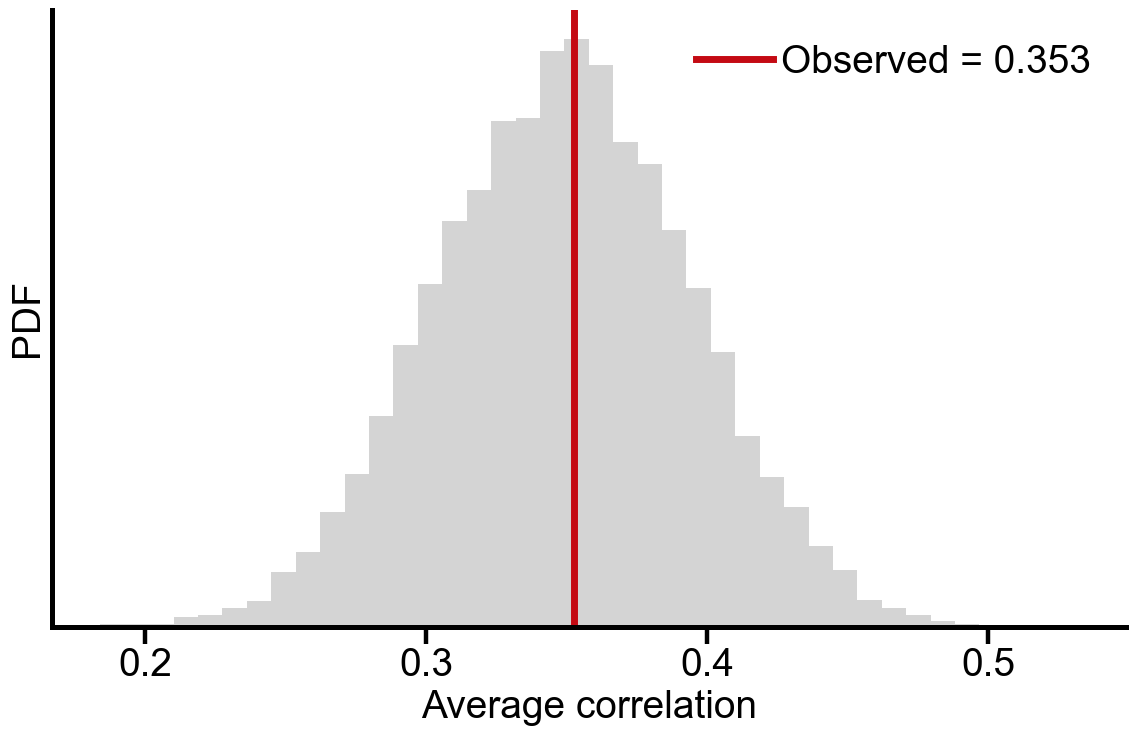

In [ ]:
from matplotlib.ticker import MaxNLocator

hist_color = "#D0D0D0"   # light gray
mean_line  = "#C40A13"   # deep red
var_line   = "#2F5597"   # deep blue

p_mean = (np.sum(np.array(random_means) >= obs_mean) + 1) / (n_perm + 1)
p_var  = (np.sum(np.array(random_vars)  <= obs_var)  + 1) / (n_perm + 1)
z_mean = (obs_mean - np.mean(random_means)) / np.std(random_means)
print(f"Observed Mean: {obs_mean:.4f}, p-value: {p_mean:.4f}, z-score: {z_mean:.2f}")

# ---------------- Figure 1: mean ----------------
fig, ax = plt.subplots(figsize=(12, 8))

ax.hist(random_means, bins=40, color=hist_color, alpha=0.9, edgecolor="none")
ax.axvline(obs_mean, color=mean_line, linewidth=5,
           label=rf"Observed = {obs_mean:.3f}")

ax.set_xlabel("Average correlation")
ax.set_ylabel("PDF")
ax.legend(frameon=False, handletextpad=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="y", left=False, labelleft=False)

ax.xaxis.set_major_locator(MaxNLocator(nbins=4))

plt.tight_layout()
fig.savefig("Supp_Figure8c1.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()